In [1]:
!pip install --no-index --find-links /kaggle/input/datasets/hinlphmhng/uav-seg-offline-assets/offline_assets/packages segmentation-models-pytorch albumentations omegaconf torchmetrics

Looking in links: /kaggle/input/datasets/hinlphmhng/uav-seg-offline-assets/offline_assets/packages
Processing /kaggle/input/datasets/hinlphmhng/uav-seg-offline-assets/offline_assets/packages/segmentation_models_pytorch-0.5.0-py3-none-any.whl


In [2]:
import os
from pathlib import Path

# 1. Thiết lập cấu hình và định nghĩa rõ các tập
INPUT_DIR = Path('/kaggle/input')

# Cấu hình chia sequence theo yêu cầu
SPLIT_CONFIG = {
    'train': ['seq1', 'seq3', 'seq4', 'seq5', 'seq8', 'seq9'],
    'val': ['seq2'],
    'test': ['seq6', 'seq7']
}

print("=== BẮT ĐẦU TÌM VÀ CHIA DATASET THEO SEQUENCE ===")

# Các list chứa đường dẫn ảnh cho từng tập
train_files = []
val_files = []
test_files = []

# 2. Duyệt qua thư mục và phân loại ảnh vào các tập tương ứng
found_sequences = set()

for dataset in INPUT_DIR.iterdir():
    if not dataset.is_dir(): continue
    
    # Tìm tất cả các thư mục có tên bắt đầu bằng 'seq' (hoặc chứa 'color')
    for seq_dir in dataset.rglob('*'):
        if seq_dir.is_dir() and (seq_dir / 'color').exists():
            seq_name = seq_dir.name
            found_sequences.add(seq_name)
            
            # Thu thập toàn bộ ảnh trong thư mục color của sequence này
            color_dir = seq_dir / 'color'
            images = list(color_dir.glob('*.png')) + list(color_dir.glob('*.jpg'))
            
            # Phân loại vào đúng list dựa trên tên sequence
            if seq_name in SPLIT_CONFIG['train']:
                train_files.extend(images)
            elif seq_name in SPLIT_CONFIG['val']:
                val_files.extend(images)
            elif seq_name in SPLIT_CONFIG['test']:
                test_files.extend(images)
            else:
                print(f"[CẢNH BÁO] Tìm thấy thư mục '{seq_name}' nhưng không nằm trong danh sách phân chia (SPLIT_CONFIG).")

# Kiểm tra xem có thiếu sequence nào không
expected_seqs = set(SPLIT_CONFIG['train'] + SPLIT_CONFIG['val'] + SPLIT_CONFIG['test'])
missing_seqs = expected_seqs - found_sequences
if missing_seqs:
    print(f"\n[LỖI CẢNH BÁO] Không tìm thấy các sequences sau trong /kaggle/input: {missing_seqs}")
    print("Vui lòng kiểm tra lại tên thư mục (có thể bị sai chữ hoa/thường, ví dụ 'Seq1' thay vì 'seq1').\n")

# Thêm chốt chặn lỗi:
total_images = len(train_files) + len(val_files) + len(test_files)
if total_images == 0:
    raise ValueError("Không tìm thấy ảnh nào! Hãy kiểm tra lại định dạng file hoặc cấu trúc thư mục.")

# 3. Hàm hỗ trợ để lấy danh sách mask tương ứng (Dùng khi training)
def get_mask_paths(image_paths):
    mask_paths = []
    for p in image_paths:
        # 1. Thử thay 'color' bằng 'label' hoặc 'labels' (các tên phổ biến)
        # và thử các đuôi file phổ biến (.png, .jpg)
        possible_mask_dirs = ['label', 'labels', 'semantic', 'masks']
        found = False
        
        for mask_dir_name in possible_mask_dirs:
            # Tạo đường dẫn thử nghiệm
            temp_path = Path(str(p).replace('/color/', f'/{mask_dir_name}/'))
            
            # Kiểm tra các đuôi file có thể có
            for ext in ['.png', '.jpg', '.jpeg']:
                test_path = temp_path.with_suffix(ext)
                if test_path.exists():
                    mask_paths.append(test_path)
                    found = True
                    break
            if found: break
            
        if not found:
            # Nếu vẫn không thấy, in ra để debug chính xác thư mục đó có gì
            parent_dir = p.parent.parent
            print(f"[CẢNH BÁO] Không tìm thấy mask cho: {p.name}")
            print(f"Thư mục sequence chứa các folder: {[d.name for d in parent_dir.iterdir() if d.is_dir()]}")
            mask_paths.append(None) # Đánh dấu lỗi
            
    return mask_paths

train_masks = get_mask_paths(train_files)
val_masks = get_mask_paths(val_files)
test_masks = get_mask_paths(test_files)

# 4. Hiển thị kết quả
print("-" * 50)
print(f"📊 KẾT QUẢ CHIA THEO SEQUENCE CỤ THỂ:")
print(f"✅ Tập TRAIN (seq1,3,4,5,8,9): {len(train_files)} ảnh")
print(f"✅ Tập VALID (seq2)          : {len(val_files)} ảnh")
print(f"✅ Tập TEST  (seq6,7)        : {len(test_files)} ảnh")
print(f"Tổng số ảnh thu thập được    : {total_images} ảnh")
print("-" * 50)

# Ví dụ kiểm tra file
if len(train_files) > 0:
    print(f"Ví dụ 1 file TRAIN: {train_files[0]}")
    print(f"Ví dụ mask TRAIN  : {train_masks[0]}")

=== BẮT ĐẦU TÌM VÀ CHIA DATASET THEO SEQUENCE ===
--------------------------------------------------
📊 KẾT QUẢ CHIA THEO SEQUENCE CỤ THỂ:
✅ Tập TRAIN (seq1,3,4,5,8,9): 8677 ảnh
✅ Tập VALID (seq2)          : 1501 ảnh
✅ Tập TEST  (seq6,7)        : 2873 ảnh
Tổng số ảnh thu thập được    : 13051 ảnh
--------------------------------------------------
Ví dụ 1 file TRAIN: /kaggle/input/datasets/leehien12/uav-forest-sunny/seq9/color/001183.png
Ví dụ mask TRAIN  : /kaggle/input/datasets/leehien12/uav-forest-sunny/seq9/labels/001183.png


In [3]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

LABEL_COLORS = [
    (0, 255, 255),    # 0: Sky
    (0, 127, 0),      # 1: Deciduous_trees
    (19, 132, 69),    # 2: Coniferous_trees
    (0, 53, 65),      # 3: Fallen_trees
    (130, 76, 0),     # 4: Dirt_ground
    (152, 251, 152),  # 5: Ground_vegetation
    (151, 126, 171),  # 6: Rocks
    (250, 150, 0),    # 7: Building
    (115, 176, 195),  # 8: Fence
    (123, 123, 123),  # 9: Car
    (0, 0, 0),        # 10: Empty
]
CLASS_NAMES = [
    'Sky', 'Deciduous_trees', 'Coniferous_trees', 'Fallen_trees',
    'Dirt_ground', 'Ground_vegetation', 'Rocks', 'Building',
    'Fence', 'Car', 'Empty',
]
NUM_CLASSES = len(CLASS_NAMES)  # = 11
PALETTE = np.array(LABEL_COLORS, dtype=np.uint8)

RGB_TO_CLASS_LUT = np.full((256, 256, 256), NUM_CLASSES - 1, dtype=np.uint8)
for cid, color in enumerate(LABEL_COLORS):
    RGB_TO_CLASS_LUT[color[0], color[1], color[2]] = cid

def fast_rgb_to_mask(rgb_arr):
    return RGB_TO_CLASS_LUT[rgb_arr[..., 0], rgb_arr[..., 1], rgb_arr[..., 2]]

def class_id_to_rgb_fast(class_map):
    return PALETTE[class_map]

In [4]:
import multiprocessing
import torch

MODEL_NAME  = 'deeplabv3plus'
ENCODER     = 'resnet50'
ENCODER_WEIGHTS = 'imagenet'
IMG_SIZE    = (1024, 1024)
BATCH_SIZE  = 4
EPOCHS      = 50
LR          = 3e-4
NUM_WORKERS = 4
PATIENCE    = 20
SAVE_TOP_K  = 3
USE_AMP     = True

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"[INFO] Device: {DEVICE}")
if DEVICE == 'cuda':
    print(f"[INFO] GPU: {torch.cuda.get_device_name()}")

[INFO] Device: cuda
[INFO] GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [5]:
import os, json
from pathlib import Path
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload

IS_KAGGLE  = os.path.exists('/kaggle')
OUTPUT_DIR = Path('/kaggle/working/outputs') if IS_KAGGLE else Path('outputs')
CKPT_DIR   = OUTPUT_DIR / 'checkpoints'
CKPT_DIR.mkdir(parents=True, exist_ok=True)

_gdrive = None
_folder_id = None
if IS_KAGGLE:
    try:
        from kaggle_secrets import UserSecretsClient
        from google.oauth2.service_account import Credentials
        s = UserSecretsClient()
        _gdrive = build('drive', 'v3', credentials=Credentials.from_service_account_info(
            json.loads(s.get_secret('GDRIVE_CREDENTIALS')),
            scopes=['https://www.googleapis.com/auth/drive.file']))
        _folder_id = s.get_secret('GDRIVE_FOLDER_ID')
        print('[OK] Google Drive ready')
    except Exception as e:
        print(f'[SKIP] Drive: {e}')

def upload_to_drive(path):
    if not _gdrive: return
    try:
        f = Path(path)
        old = _gdrive.files().list(
            q=f"name='{f.name}' and '{_folder_id}' in parents and trashed=false",
            fields='files(id)').execute().get('files', [])
        media = MediaFileUpload(str(f), mimetype='application/octet-stream', resumable=True)
        if old: _gdrive.files().update(fileId=old[0]['id'], media_body=media).execute()
        else:   _gdrive.files().create(body={'name': f.name, 'parents': [_folder_id]}, media_body=media).execute()
        print(f'  [DRIVE] {f.name} ({f.stat().st_size/1024**2:.1f}MB)')
    except Exception as e:
        print(f'  [DRIVE FAIL] {e}')

[SKIP] Drive: Connection error trying to communicate with service.


In [6]:
import torch

class CheckpointSaver:
    def __init__(self, dirpath, top_k=3, maximize=True):
        self.dirpath  = dirpath
        self.top_k    = top_k
        self.maximize = maximize
        self.saved_ckpts = []  # list of (score, filepath)

    def save_if_best(self, state_dict, epoch, current_score):
        filename = f"epoch_{epoch:03d}_miou_{current_score:.4f}.pth"
        filepath = os.path.join(self.dirpath, filename)

        self.saved_ckpts.append((current_score, filepath))
        self.saved_ckpts.sort(key=lambda x: x[0], reverse=self.maximize)

        top_k_paths = [ckpt[1] for ckpt in self.saved_ckpts[:self.top_k]]

        if filepath in top_k_paths:
            torch.save(state_dict, filepath)
            print(f'  * [TOP {self.top_k}] mIoU: {current_score:.4f} -> {filename}')
            upload_to_drive(filepath)

            # Xóa checkpoint ngoài top-k
            while len(self.saved_ckpts) > self.top_k:
                _, removed = self.saved_ckpts.pop()  # xóa phần tử tệ nhất
                if os.path.exists(removed):
                    os.remove(removed)
            return True
        else:
            # Không lọt top-k, chưa lưu file nên chỉ cần xóa khỏi list
            self.saved_ckpts = [c for c in self.saved_ckpts if c[1] != filepath]
            return False

In [7]:
import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from PIL import Image
import albumentations as A
from albumentations.pytorch import ToTensorV2

INPUT_DIR = Path('/kaggle/input')
SPLIT_CONFIG = {
    'train': ['seq1', 'seq3', 'seq4', 'seq5', 'seq8', 'seq9'],
    'val':   ['seq2'],
    'test':  ['seq6', 'seq7']
}

def collect_data():
    data = {'train': [], 'val': [], 'test': []}
    for dataset_path in INPUT_DIR.iterdir():
        if not dataset_path.is_dir(): continue
        for color_dir in dataset_path.rglob('color'):
            seq_dir  = color_dir.parent
            seq_name = seq_dir.name
            # Tìm folder mask
            mask_dir = seq_dir / 'label'
            if not mask_dir.exists():
                mask_dir = seq_dir / 'labels'
            if not mask_dir.exists(): continue
            # Xác định tập
            target_set = None
            for key, seq_list in SPLIT_CONFIG.items():
                if seq_name in seq_list:
                    target_set = key
                    break
            if not target_set: continue
            # Ghép cặp ảnh - mask
            for img_p in sorted(list(color_dir.glob('*.png')) + list(color_dir.glob('*.jpg'))):
                mask_p = (mask_dir / img_p.name).with_suffix('.png')
                if not mask_p.exists():
                    mask_p = (mask_dir / img_p.name).with_suffix('.jpg')
                if mask_p.exists():
                    data[target_set].append((str(img_p), str(mask_p)))
    return data['train'], data['val'], data['test']

train_files, val_files, test_files = collect_data()
print(f"[INFO] Train: {len(train_files)} | Val: {len(val_files)} | Test: {len(test_files)}")

if len(train_files) == 0:
    raise ValueError("Không tìm thấy dữ liệu! Kiểm tra lại cấu trúc thư mục.")

class ForestDataset(Dataset):
    def __init__(self, file_list, transform=None):
        self.file_list = file_list
        self.transform = transform

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        img_path, mask_path = self.file_list[idx]
        img      = np.array(Image.open(img_path).convert('RGB'))
        mask_rgb = np.array(Image.open(mask_path).convert('RGB'))
        mask     = fast_rgb_to_mask(mask_rgb)
        if self.transform:
            aug  = self.transform(image=img, mask=mask)
            img, mask = aug['image'], aug['mask']
        return img, mask.long()

train_tf = A.Compose([
    A.Resize(*IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(scale_limit=0.1, rotate_limit=15, p=0.3, border_mode=0),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])
val_tf = A.Compose([
    A.Resize(*IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

train_ds = ForestDataset(train_files, train_tf)
val_ds   = ForestDataset(val_files,   val_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
print(f'[OK] Dataloaders ready. Train: {len(train_loader)} batches | Val: {len(val_loader)} batches')

/usr/local/lib/python3.12/dist-packages/albumentations/check_version.py:147: UserWarning: Error fetching version info <urlopen error [Errno -3] Temporary failure in name resolution>
  data = fetch_version_info()


[INFO] Train: 8677 | Val: 1501 | Test: 2873
[OK] Dataloaders ready. Train: 2169 batches | Val: 376 batches


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [8]:
import shutil, glob
import torch.nn as nn
import segmentation_models_pytorch as smp

print("=== CHUẨN BỊ TRỌNG SỐ OFFLINE ===")
CACHE_DIR = '/root/.cache/torch/hub/checkpoints/'
os.makedirs(CACHE_DIR, exist_ok=True)

# ✅ Sửa path Kaggle dataset
WEIGHT_DIR = '/kaggle/input/datasets/itmeagain77/resnet50-pytorch-weights'
pth_files  = glob.glob(os.path.join(WEIGHT_DIR, '*.pth'))
if pth_files:
    cache_file = os.path.join(CACHE_DIR, 'resnet50-19c8e357.pth')
    if not os.path.exists(cache_file):
        shutil.copy(pth_files[0], cache_file)
        print(f"[OK] Đã copy: {os.path.basename(pth_files[0])} -> Cache")
    else:
        print("[OK] Trọng số đã có trong cache.")
else:
    print("[CẢNH BÁO] Không tìm thấy .pth offline, sẽ tải từ Internet.")

# ✅ Sửa segformer dùng đúng class smp.Segformer
MODELS = {
    'unet':          lambda: smp.Unet(encoder_name=ENCODER, encoder_weights='imagenet', in_channels=3, classes=NUM_CLASSES),
    'unetpp':        lambda: smp.UnetPlusPlus(encoder_name=ENCODER, encoder_weights='imagenet', in_channels=3, classes=NUM_CLASSES),
    'deeplabv3plus': lambda: smp.DeepLabV3Plus(encoder_name=ENCODER, encoder_weights='imagenet', in_channels=3, classes=NUM_CLASSES),
    'segformer':     lambda: smp.Segformer(encoder_name=ENCODER, encoder_weights='imagenet', in_channels=3, classes=NUM_CLASSES),  # ✅
}

if MODEL_NAME not in MODELS:
    raise ValueError(f"MODEL_NAME '{MODEL_NAME}' không hợp lệ. Chọn trong: {list(MODELS.keys())}")

model = MODELS[MODEL_NAME]().to(DEVICE)
print(f'🚀 MODEL: {MODEL_NAME} | Encoder: {ENCODER} | Classes: {NUM_CLASSES}')
print(f'📊 Params: {sum(p.numel() for p in model.parameters()):,}')

=== CHUẨN BỊ TRỌNG SỐ OFFLINE ===
[OK] Đã copy: resnet50-19c8e357.pth -> Cache


'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/smp-hub/resnet50.imagenet/resolve/00cb74e366966d59cd9a35af57e618af9f88efe9/config.json
Retrying in 1s [Retry 1/5].
/usr/local/lib/python3.12/dist-packages/segmentation_models_pytorch/encoders/__init__.py:136: UserWarning: Error loading resnet50 `imagenet` weights from Hugging Face Hub, trying loading from original url...
  warnings.warn(message, UserWarning)


🚀 MODEL: deeplabv3plus | Encoder: resnet50 | Classes: 11
📊 Params: 26,680,155


In [9]:
class FocalDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()
        # 11 classes -> MULTICLASS_MODE
        self.focal = smp.losses.FocalLoss(mode=smp.losses.MULTICLASS_MODE, gamma=2.0)
        self.dice  = smp.losses.DiceLoss(mode=smp.losses.MULTICLASS_MODE, from_logits=True)

    def forward(self, logits, targets):
        return self.focal(logits, targets) + self.dice(logits, targets)

criterion = FocalDiceLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler    = torch.amp.GradScaler('cuda', enabled=USE_AMP)

print("✅ Đã khởi tạo Loss, Optimizer, Scheduler, Scaler!")

✅ Đã khởi tạo Loss, Optimizer, Scheduler, Scaler!


In [10]:
from tqdm import tqdm
# Tính pixel frequency trên tập train
def compute_class_weights(file_list, num_classes, c=1.02):
    counts = np.zeros(num_classes, dtype=np.int64)
    for _, mask_path in tqdm(file_list, desc='Computing class weights'):
        mask_rgb = np.array(Image.open(mask_path).convert('RGB'))
        mask = fast_rgb_to_mask(mask_rgb)
        for cid in range(num_classes):
            counts[cid] += (mask == cid).sum()
    total = counts.sum()
    freq = counts / total  # p_class
    weights = 1.0 / np.log(c + freq)  # w_class = 1/ln(c + p)
    weights = weights / weights.sum() * num_classes  # normalize
    return torch.tensor(weights, dtype=torch.float32).to(DEVICE)

class_weights = compute_class_weights(train_files, NUM_CLASSES)
print("Class weights:", class_weights)

# Đưa vào loss
class FocalDiceLoss(nn.Module):
    def __init__(self, class_weights=None):
        super().__init__()
        self.focal = smp.losses.FocalLoss(mode=smp.losses.MULTICLASS_MODE, gamma=2.0)
        self.dice  = smp.losses.DiceLoss(mode=smp.losses.MULTICLASS_MODE, 
                                          from_logits=True, classes=list(range(NUM_CLASSES-1)))
        self.ce    = nn.CrossEntropyLoss(weight=class_weights, ignore_index=NUM_CLASSES-1)

    def forward(self, logits, targets):
        return self.focal(logits, targets) + self.dice(logits, targets) + 0.5 * self.ce(logits, targets)

Computing class weights: 100%|██████████| 8677/8677 [02:54<00:00, 49.66it/s]


Class weights: tensor([0.2375, 0.2123, 0.1329, 1.4115, 0.9150, 0.1129, 0.9353, 1.6549, 1.8018,
        1.7724, 1.8135], device='cuda:0')


In [11]:
import time, gc
import csv
import numpy as np
import torch
from tqdm import tqdm

def get_miou(cm, n_ignore_last=1):
    """Tính mIoU, bỏ qua n class cuối (mặc định bỏ class Empty)"""
    inter = np.diag(cm)
    union = cm.sum(1) + cm.sum(0) - inter
    iou   = np.where(union > 0, inter / union, 0.0)
    valid_iou   = iou[:-n_ignore_last]
    valid_union = union[:-n_ignore_last]
    miou = valid_iou[valid_union > 0].mean() if any(valid_union > 0) else 0.0
    return miou, iou

best_val_miou = -float('inf')
no_improve    = 0
saver         = CheckpointSaver(dirpath=CKPT_DIR, top_k=SAVE_TOP_K, maximize=True)

# 1. KHỞI TẠO FILE LOG VÀ HEADER (ĐỂ NGOÀI VÒNG LẶP)
LOG_FILE = OUTPUT_DIR / 'training_log.csv'
with open(LOG_FILE, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['epoch', 'train_loss', 'val_loss', 'miou', 
                     *CLASS_NAMES[:-1]])  # header

# BẮT ĐẦU VÒNG LẶP HUẤN LUYỆN
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()

    # --- TRAIN ---
    model.train()
    train_loss, n_train = 0.0, 0
    pbar_train = tqdm(train_loader, desc=f'E{epoch} [TRAIN]')
    for imgs, masks in pbar_train:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            out  = model(imgs)
            loss = criterion(out, masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        train_loss += loss.item()
        n_train    += 1
        pbar_train.set_postfix({'loss': f'{loss.item():.4f}'})

    # --- VAL ---
    model.eval()
    val_loss, n_val = 0.0, 0
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    pbar_val = tqdm(val_loader, desc=f'E{epoch} [VAL]')
    with torch.no_grad():
        for imgs, masks in pbar_val:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=USE_AMP):
                out       = model(imgs)
                val_loss += criterion(out, masks).item()
                n_val    += 1
            preds = out.argmax(1)
            p = preds.detach().cpu().numpy().flatten()
            t = masks.detach().cpu().numpy().flatten()
            mask_valid = (t >= 0) & (t < NUM_CLASSES)
            cm += np.bincount(
                t[mask_valid] * NUM_CLASSES + p[mask_valid],
                minlength=NUM_CLASSES ** 2
            ).reshape(NUM_CLASSES, NUM_CLASSES)

    # --- METRICS ---
    avg_train_loss = train_loss / n_train
    avg_val_loss   = val_loss   / n_val
    miou, class_ious = get_miou(cm)
    scheduler.step()

    print(f'\n▶ Epoch {epoch:03d} | Train: {avg_train_loss:.4f} | Val: {avg_val_loss:.4f} | mIoU: {miou:.4f} | {time.time()-t0:.0f}s')

    # 2. GHI KẾT QUẢ VÀO FILE LOG (BÊN TRONG VÒNG LẶP)
    with open(LOG_FILE, 'a', newline='') as f:
        writer = csv.writer(f)
        writer.writerow([epoch, avg_train_loss, avg_val_loss, miou,
                         *[f'{class_ious[i]:.4f}' for i in range(NUM_CLASSES-1)]])

    # --- SAVE & EARLY STOPPING ---
    checkpoint_dict = {
        'epoch': epoch,
        'model_state_dict':     model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'miou': miou
    }
    is_best = saver.save_if_best(state_dict=checkpoint_dict, epoch=epoch, current_score=miou)

    if is_best:
        best_val_miou = miou
        no_improve    = 0
        print(f"  ⭐ Kỷ lục mới! Class-wise IoU:")
        for i, name in enumerate(CLASS_NAMES[:-1]):
            print(f"    - {name:18s}: {class_ious[i]:.4f}")
    else:
        no_improve += 1

    del cm
    gc.collect()
    torch.cuda.empty_cache()

    if no_improve >= PATIENCE:
        print(f'🛑 Early Stopping tại Epoch {epoch}')
        break

print(f'\n✅ Huấn luyện hoàn tất! Best mIoU: {best_val_miou:.4f}')

E1 [VAL]: 100%|██████████| 376/376 [00:27<00:00, 13.81it/s]
/tmp/ipykernel_161/782836379.py:11: RuntimeWarning: invalid value encountered in divide
  iou   = np.where(union > 0, inter / union, 0.0)



▶ Epoch 001 | Train: 0.5982 | Val: 0.3395 | mIoU: 0.5981 | 219s
  * [TOP 3] mIoU: 0.5981 -> epoch_001_miou_0.5981.pth
  ⭐ Kỷ lục mới! Class-wise IoU:
    - Sky               : 0.0000
    - Deciduous_trees   : 0.7096
    - Coniferous_trees  : 0.7652
    - Fallen_trees      : 0.5041
    - Dirt_ground       : 0.8246
    - Ground_vegetation : 0.8408
    - Rocks             : 0.8022
    - Building          : 0.8341
    - Fence             : 0.0052
    - Car               : 0.6952


E2 [VAL]: 100%|██████████| 376/376 [00:27<00:00, 13.83it/s]



▶ Epoch 002 | Train: 0.4268 | Val: 0.3225 | mIoU: 0.6581 | 215s
  * [TOP 3] mIoU: 0.6581 -> epoch_002_miou_0.6581.pth
  ⭐ Kỷ lục mới! Class-wise IoU:
    - Sky               : 0.0000
    - Deciduous_trees   : 0.7307
    - Coniferous_trees  : 0.7688
    - Fallen_trees      : 0.4619
    - Dirt_ground       : 0.7794
    - Ground_vegetation : 0.8518
    - Rocks             : 0.8031
    - Building          : 0.8808
    - Fence             : 0.5484
    - Car               : 0.7559


E3 [VAL]: 100%|██████████| 376/376 [00:27<00:00, 13.78it/s]



▶ Epoch 003 | Train: 0.3932 | Val: 0.3085 | mIoU: 0.6762 | 215s
  * [TOP 3] mIoU: 0.6762 -> epoch_003_miou_0.6762.pth
  ⭐ Kỷ lục mới! Class-wise IoU:
    - Sky               : 0.0000
    - Deciduous_trees   : 0.7369
    - Coniferous_trees  : 0.7717
    - Fallen_trees      : 0.5537
    - Dirt_ground       : 0.8258
    - Ground_vegetation : 0.8545
    - Rocks             : 0.8152
    - Building          : 0.8872
    - Fence             : 0.5398
    - Car               : 0.7774


... (90 outputs left out)

E49 [VAL]: 100%|██████████| 376/376 [00:27<00:00, 13.75it/s]



▶ Epoch 049 | Train: 0.2844 | Val: 0.2347 | mIoU: 0.7362 | 215s
  * [TOP 3] mIoU: 0.7362 -> epoch_049_miou_0.7362.pth
  ⭐ Kỷ lục mới! Class-wise IoU:
    - Sky               : 0.0000
    - Deciduous_trees   : 0.7651
    - Coniferous_trees  : 0.8055
    - Fallen_trees      : 0.6843
    - Dirt_ground       : 0.8726
    - Ground_vegetation : 0.8797
    - Rocks             : 0.8516
    - Building          : 0.9218
    - Fence             : 0.7278
    - Car               : 0.8535


E50 [VAL]: 100%|██████████| 376/376 [00:27<00:00, 13.84it/s]



▶ Epoch 050 | Train: 0.2840 | Val: 0.2357 | mIoU: 0.7357 | 214s

✅ Huấn luyện hoàn tất! Best mIoU: 0.7362


In [12]:
import shutil
from IPython.display import FileLink
import os

# 1. Định nghĩa tên file zip và đường dẫn thư mục checkpoint
checkpoint_folder = '/kaggle/working/outputs/checkpoints'
output_zip_name = '/kaggle/working/my_forest_checkpoints'

# 2. Tiến hành nén thư mục (Sẽ tạo ra file my_forest_checkpoints.zip)
if os.path.exists(checkpoint_folder):
    shutil.make_archive(output_zip_name, 'zip', checkpoint_folder)
    print(f"✅ Đã nén xong! File lưu tại: {output_zip_name}.zip")
    
    # 3. Tạo link để click và tải về ngay lập tức
    display(FileLink(f'my_forest_checkpoints.zip'))
else:
    print(f"❌ Không tìm thấy thư mục: {checkpoint_folder}. Hãy kiểm tra lại đường dẫn!")

✅ Đã nén xong! File lưu tại: /kaggle/working/my_forest_checkpoints.zip


/kaggle/working/my_forest_checkpoints.zip

In [13]:
import torch
import numpy as np
from tqdm import tqdm
from PIL import Image
import matplotlib.pyplot as plt

# 1. Load Checkpoint tốt nhất
BEST_CKPT = '/kaggle/working/outputs/checkpoints/epoch_050_miou_0.7439.pth' 

if os.path.exists(BEST_CKPT):
    print(f"🔄 Đang nạp model tốt nhất từ: {BEST_CKPT}")
    ckpt = torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt['model_state_dict'])
    print(f"✅ Đã nạp thành công mIoU kỷ lục: {ckpt.get('miou', ckpt.get('metric', 0)):.4f}")
else:
    print("⚠️ Cảnh báo: Không tìm thấy file checkpoint. Đang dùng model hiện tại trong RAM.")

# 2. Khởi tạo Dataloader cho tập Test
test_ds = ForestDataset(test_files, val_tf) # Dùng val_tf (không augment)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

# 3. Vòng lặp Test
model.eval()
cm_test = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

print(f"🚀 Đang chạy Test trên {len(test_files)} ảnh...")
with torch.no_grad():
    for imgs, masks in tqdm(test_loader, desc='Testing'):
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            out = model(imgs)
            
        preds = out.argmax(1).detach().cpu().numpy().flatten()
        targets = masks.detach().cpu().numpy().flatten()
        
        mask_valid = (targets >= 0) & (targets < NUM_CLASSES)
        cm_test += np.bincount(
            targets[mask_valid] * NUM_CLASSES + preds[mask_valid], 
            minlength=NUM_CLASSES**2
        ).reshape(NUM_CLASSES, NUM_CLASSES)

# 4. Tính toán kết quả cuối cùng
miou_test, ious_test = get_miou(cm_test)

print("\n" + "="*50)
print(f"📊 KẾT QUẢ ĐÁNH GIÁ TẬP TEST (SEQ6, SEQ7)")
print("="*50)
for i, name in enumerate(CLASS_NAMES[:-1]):
    status = f"{ious_test[i]:.4f}" if cm_test.sum(1)[i] > 0 else "N/A"
    print(f"  - {name:18s}: {status}")
print("-" * 50)
print(f"🌟 MEAN IoU (OVERALL): {miou_test:.4f}")
print("="*50)

⚠️ Cảnh báo: Không tìm thấy file checkpoint. Đang dùng model hiện tại trong RAM.
🚀 Đang chạy Test trên 2873 ảnh...


Testing: 100%|██████████| 719/719 [00:52<00:00, 13.82it/s]


📊 KẾT QUẢ ĐÁNH GIÁ TẬP TEST (SEQ6, SEQ7)
  - Sky               : 0.9910
  - Deciduous_trees   : 0.7042
  - Coniferous_trees  : 0.8258
  - Fallen_trees      : 0.6248
  - Dirt_ground       : 0.8839
  - Ground_vegetation : 0.8335
  - Rocks             : 0.8573
  - Building          : 0.9048
  - Fence             : 0.5897
  - Car               : 0.8239
--------------------------------------------------
🌟 MEAN IoU (OVERALL): 0.8039



/tmp/ipykernel_161/782836379.py:11: RuntimeWarning: invalid value encountered in divide
  iou   = np.where(union > 0, inter / union, 0.0)


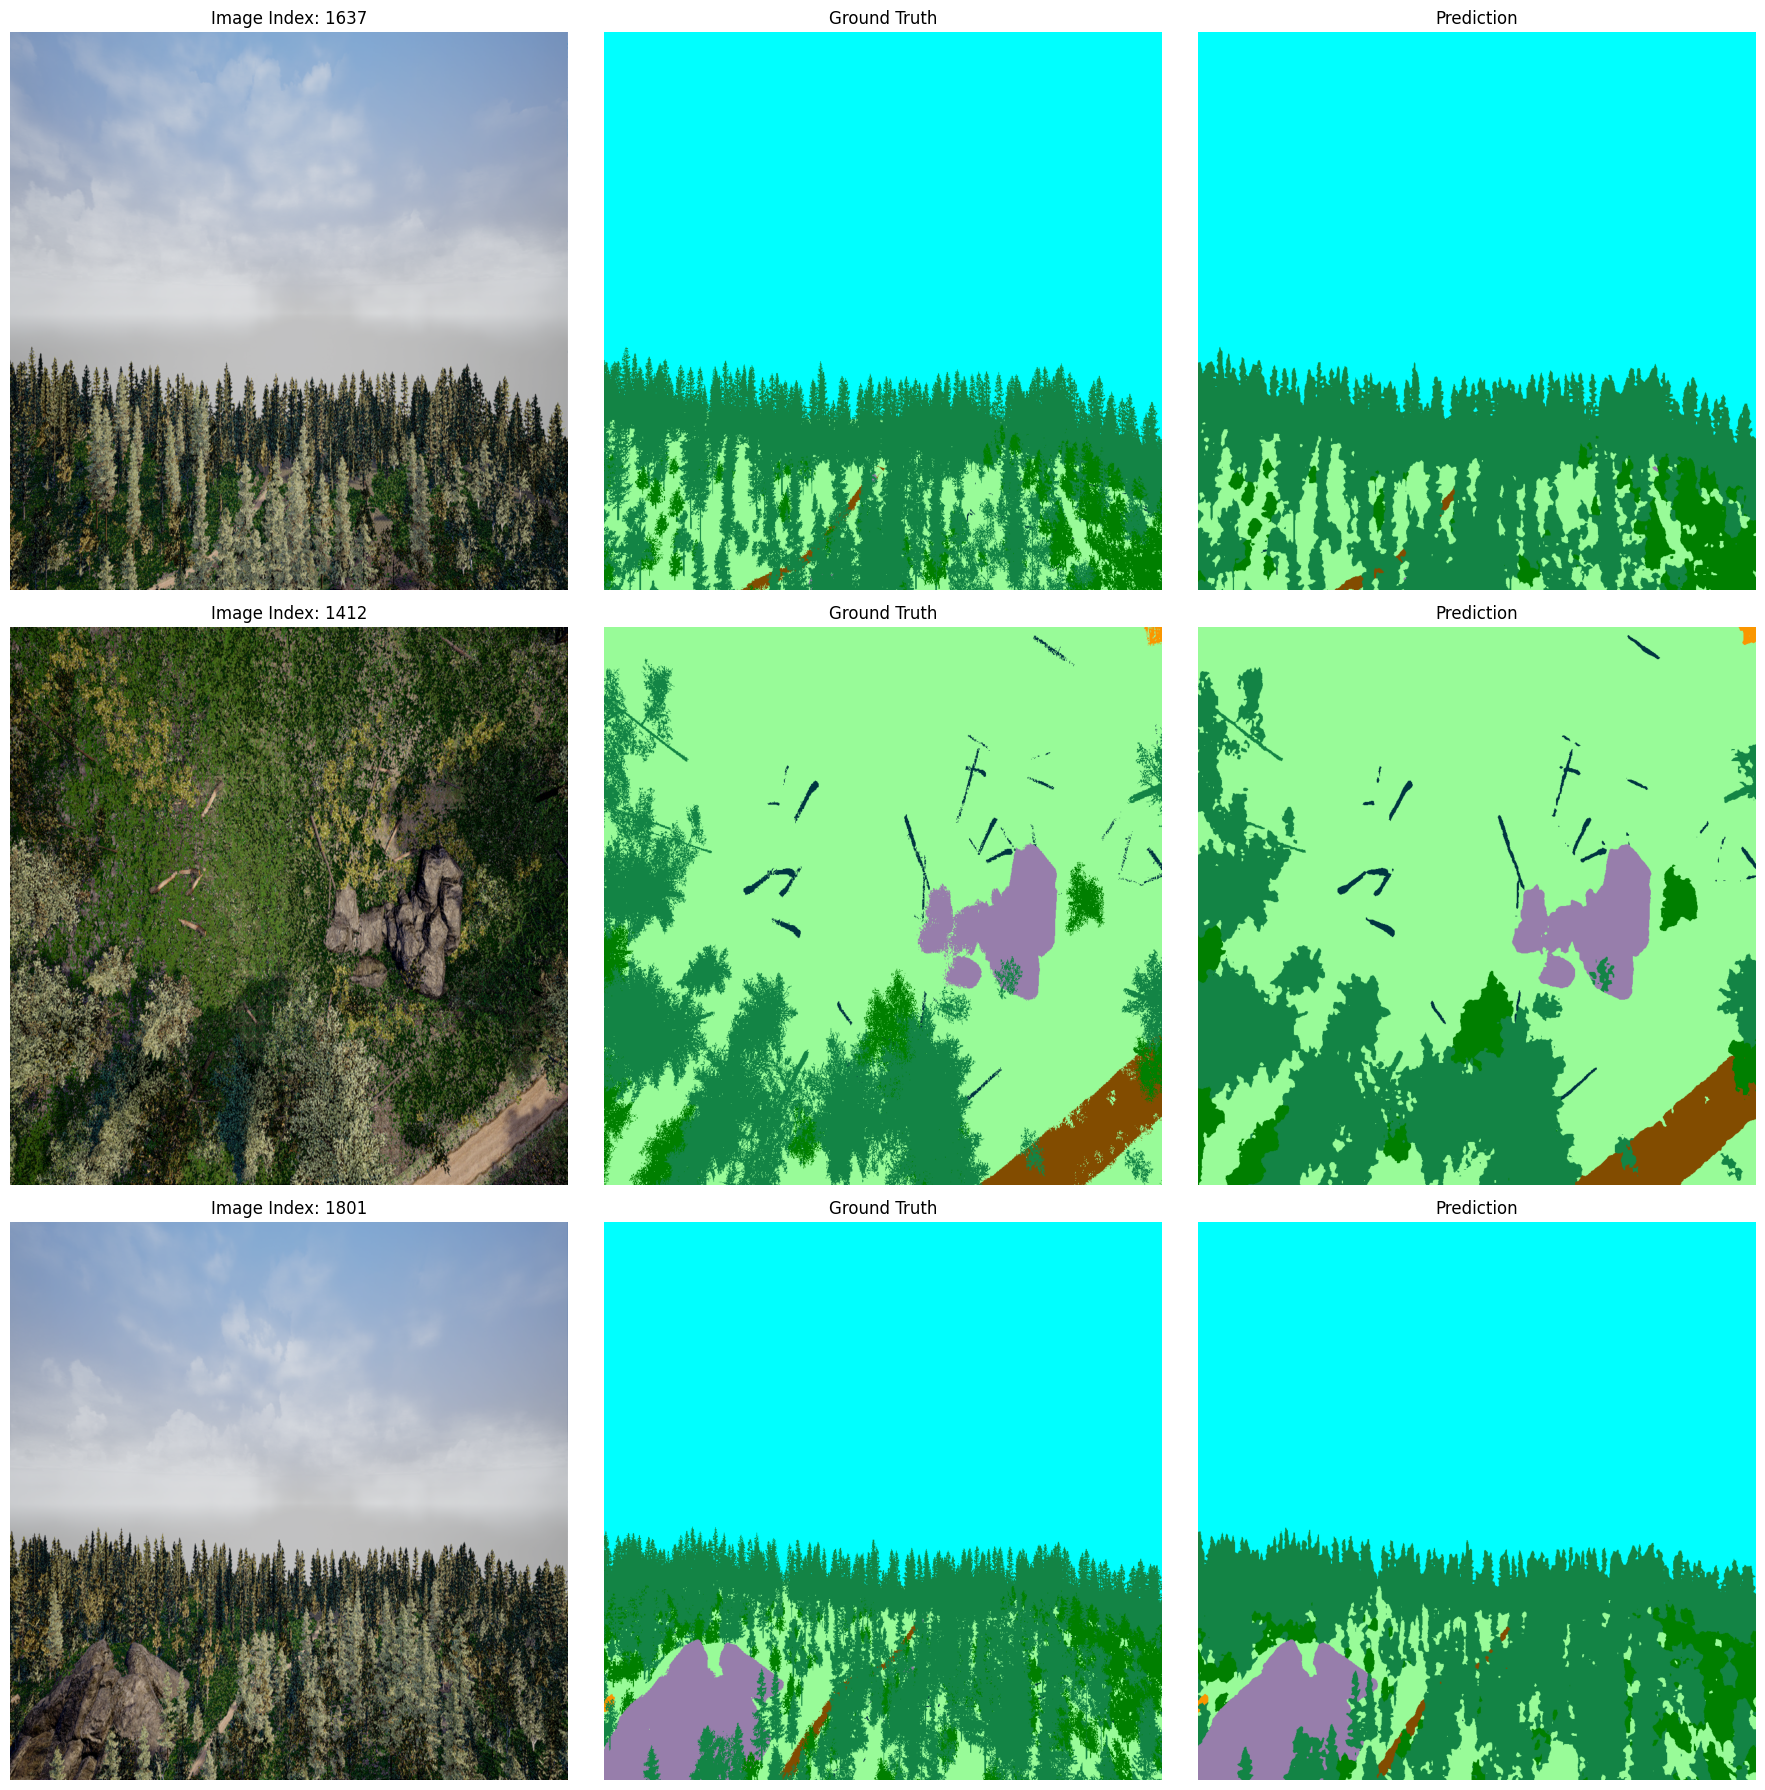

In [14]:
def visualize_predictions(dataset, model, num_samples=3):
    model.eval()
    indices = np.random.choice(len(dataset), num_samples, replace=False)
    
    plt.figure(figsize=(18, 6 * num_samples))
    
    for i, idx in enumerate(indices):
        img_tensor, mask_id = dataset[idx]
        
        # Inference
        with torch.no_grad():
            input_tensor = img_tensor.unsqueeze(0).to(DEVICE)
            out = model(input_tensor)
            pred_id = out.argmax(1).squeeze(0).cpu().numpy()
            
        # Chuyển đổi về RGB để hiển thị
        img_show = img_tensor.permute(1, 2, 0).numpy()
        # Un-normalize ảnh để hiển thị đúng màu
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img_show = std * img_show + mean
        img_show = np.clip(img_show, 0, 1)
        
        gt_rgb = class_id_to_rgb_fast(mask_id.numpy())
        pred_rgb = class_id_to_rgb_fast(pred_id)
        
        # Vẽ đồ thị
        plt.subplot(num_samples, 3, i*3 + 1)
        plt.imshow(img_show)
        plt.title(f"Image Index: {idx}")
        plt.axis('off')
        
        plt.subplot(num_samples, 3, i*3 + 2)
        plt.imshow(gt_rgb)
        plt.title("Ground Truth")
        plt.axis('off')
        
        plt.subplot(num_samples, 3, i*3 + 3)
        plt.imshow(pred_rgb)
        plt.title("Prediction")
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()

# Chạy thử hiển thị 3 mẫu ngẫu nhiên từ tập Test
visualize_predictions(test_ds, model, num_samples=3)

In [15]:
import shutil
import os
from IPython.display import FileLink

# 1. Định nghĩa các đường dẫn
output_dir = '/kaggle/working/outputs'
log_dir = '/kaggle/working/outputs/logs'
# Thư mục chứa các file zip tải về
export_zip_path = '/kaggle/working/final_training_results'

# 2. Tạo một thư mục tạm để gom các file nhẹ (logs, txt, csv)
# Chúng ta sẽ không gom thư mục 'checkpoints' vì nó rất nặng và bạn đã tải rồi
temp_export_dir = '/kaggle/working/temp_results_for_report'
if os.path.exists(temp_export_dir):
    shutil.rmtree(temp_export_dir)
os.makedirs(temp_export_dir)

# Copy thư mục logs vào thư mục tạm
if os.path.exists(log_dir):
    shutil.copytree(log_dir, os.path.join(temp_export_dir, 'logs'))
    print("✅ Đã gom thư mục Logs.")

# Quét và copy các file văn bản (.txt, .csv, .json) trong thư mục output nếu có
for root, dirs, files in os.walk(output_dir):
    if 'checkpoints' in root: continue # Bỏ qua thư mục checkpoints
    for file in files:
        if file.endswith(('.txt', '.csv', '.json', '.png')):
            src_path = os.path.join(root, file)
            shutil.copy(src_path, temp_export_dir)

# 3. Nén tất cả lại thành file ZIP
shutil.make_archive(export_zip_path, 'zip', temp_export_dir)

print("-" * 50)
print(f"🎉 Đã nén xong toàn bộ kết quả báo cáo!")
print(f"📁 File: {export_zip_path}.zip")
print("-" * 50)

# 4. Hiển thị link tải
display(FileLink('final_training_results.zip'))

--------------------------------------------------
🎉 Đã nén xong toàn bộ kết quả báo cáo!
📁 File: /kaggle/working/final_training_results.zip
--------------------------------------------------


/kaggle/working/final_training_results.zip